In [1]:
# Week 4 — Day 4: Hypothesis Testing
# Cynaris Internship

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Libraries imported successfully!
NumPy version: 2.5.3
Pandas version: 3.0.6


In [2]:
# Business Scenario: Employee Productivity

data = {
    "Employee": [f"Employee_{i}" for i in range(1, 21)],
    "Productivity_Score": [
        72, 68, 75, 80, 71, 69, 77, 74, 73, 76,
        70, 78, 72, 74, 81, 67, 75, 73, 79, 71
    ],
    "Department": [
        "Sales", "Sales", "IT", "IT", "HR",
        "HR", "Sales", "IT", "HR", "Sales",
        "IT", "HR", "Sales", "IT", "HR",
        "Sales", "IT", "HR", "Sales", "IT"
    ]
}

df = pd.DataFrame(data)

print("Employee Productivity Dataset")
display(df.head(10))

print("\nDataset shape:", df.shape)
print("\nAverage productivity score:", df["Productivity_Score"].mean())

Employee Productivity Dataset


,Employee,Productivity_Score,Department
0,Employee_1,72,Sales
1,Employee_2,68,Sales
2,Employee_3,75,IT
3,Employee_4,80,IT
4,Employee_5,71,HR
5,Employee_6,69,HR
6,Employee_7,77,Sales
7,Employee_8,74,IT
8,Employee_9,73,HR
9,Employee_10,76,Sales



Dataset shape: (20, 3)

Average productivity score: 73.75


## 1. Business Scenarios and Hypotheses

### Scenario 1: Employee Productivity
- H₀ (Null Hypothesis): The average employee productivity score is 75.
- H₁ (Alternative Hypothesis): The average employee productivity score is different from 75.

### Scenario 2: Training Effectiveness
- H₀: The average productivity score is the same for trained and untrained employees.
- H₁: The average productivity score differs between trained and untrained employees.

### Scenario 3: Department Performance
- H₀: The average productivity scores of Sales and IT employees are equal.
- H₁: The average productivity scores of Sales and IT employees are different.

In [3]:
# Display the three business scenarios

scenarios = {
    "Scenario 1": "Is average employee productivity different from 75?",
    "Scenario 2": "Do trained and untrained employees have different productivity?",
    "Scenario 3": "Do Sales and IT employees have different average productivity?"
}

for scenario, question in scenarios.items():
    print(f"{scenario}: {question}")

Scenario 1: Is average employee productivity different from 75?
Scenario 2: Do trained and untrained employees have different productivity?
Scenario 3: Do Sales and IT employees have different average productivity?


In [4]:
# 2. One-Sample T-Test

# Hypotheses:
# H0: The population mean productivity score is 75.
# H1: The population mean productivity score is different from 75.

hypothesized_mean = 75

sample_scores = df["Productivity_Score"]

t_statistic, p_value = stats.ttest_1samp(
    sample_scores,
    popmean=hypothesized_mean
)

confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(sample_scores) - 1,
    loc=sample_scores.mean(),
    scale=stats.sem(sample_scores)
)

print("ONE-SAMPLE T-TEST RESULTS")
print("-" * 35)
print(f"Sample size: {len(sample_scores)}")
print(f"Sample mean: {sample_scores.mean():.2f}")
print(f"Hypothesized population mean: {hypothesized_mean}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4f}")
print(f"95% Confidence Interval: ({confidence_interval[0]:.2f}, {confidence_interval[1]:.2f})")

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Interpretation: The mean productivity score differs significantly from 75.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Interpretation: There is insufficient evidence that the mean differs from 75.")

ONE-SAMPLE T-TEST RESULTS
-----------------------------------
Sample size: 20
Sample mean: 73.75
Hypothesized population mean: 75
T-statistic: -1.4217
P-value: 0.1713
95% Confidence Interval: (71.91, 75.59)

Decision: Fail to reject the null hypothesis.
Interpretation: There is insufficient evidence that the mean differs from 75.


In [5]:
# 3. Two-Sample T-Test: Training Effectiveness

# Create sample training groups for demonstration
trained = np.array([78, 82, 75, 80, 85, 79, 77, 83, 81, 76])
untrained = np.array([70, 72, 68, 75, 71, 69, 73, 67, 74, 70])

# Hypotheses:
# H0: The mean productivity scores are equal.
# H1: The mean productivity scores are different.

t_statistic, p_value = stats.ttest_ind(
    trained,
    untrained,
    equal_var=False
)

print("TWO-SAMPLE T-TEST RESULTS")
print("-" * 35)
print(f"Trained group mean: {trained.mean():.2f}")
print(f"Untrained group mean: {untrained.mean():.2f}")
print(f"Mean difference: {trained.mean() - untrained.mean():.2f}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.6f}")

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("Interpretation: The groups have significantly different mean productivity scores.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("Interpretation: There is insufficient evidence of a difference between the group means.")

TWO-SAMPLE T-TEST RESULTS
-----------------------------------
Trained group mean: 79.60
Untrained group mean: 70.90
Mean difference: 8.70
T-statistic: 6.6661
P-value: 0.000004

Decision: Reject the null hypothesis.
Interpretation: The groups have significantly different mean productivity scores.


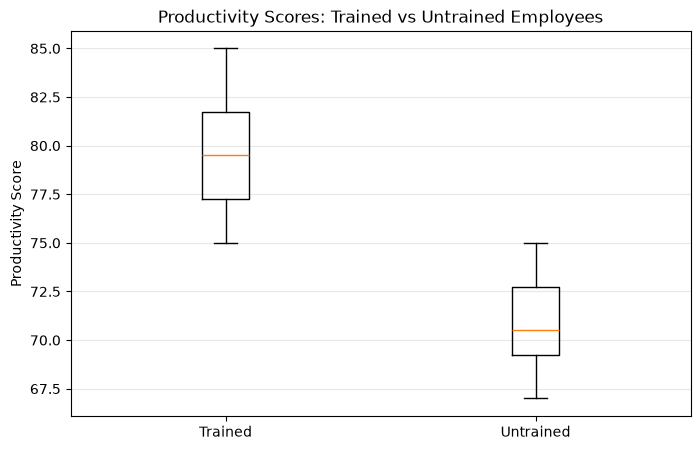

In [6]:
# Compare productivity scores between the two groups

plt.figure(figsize=(8, 5))

plt.boxplot(
    [trained, untrained],
    tick_labels=["Trained", "Untrained"]
)

plt.title("Productivity Scores: Trained vs Untrained Employees")
plt.ylabel("Productivity Score")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [7]:
# 4. Two-Sample T-Test: Sales vs IT

sales_scores = df.loc[
    df["Department"] == "Sales", "Productivity_Score"
]

it_scores = df.loc[
    df["Department"] == "IT", "Productivity_Score"
]

# H0: Sales and IT have equal mean productivity.
# H1: Sales and IT have different mean productivity.

t_statistic, p_value = stats.ttest_ind(
    sales_scores,
    it_scores,
    equal_var=False
)

print("SALES VS IT: TWO-SAMPLE T-TEST")
print("-" * 40)
print(f"Sales sample size: {len(sales_scores)}")
print(f"IT sample size: {len(it_scores)}")
print(f"Sales mean: {sales_scores.mean():.2f}")
print(f"IT mean: {it_scores.mean():.2f}")
print(f"T-statistic: {t_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("There is evidence of a difference in mean productivity.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is insufficient evidence of a difference in mean productivity.")

SALES VS IT: TWO-SAMPLE T-TEST
----------------------------------------
Sales sample size: 7
IT sample size: 7
Sales mean: 73.00
IT mean: 74.14
T-statistic: -0.5418
P-value: 0.5989

Decision: Fail to reject the null hypothesis.
There is insufficient evidence of a difference in mean productivity.


## 5. Type I and Type II Errors in Business

### Type I Error (False Positive)
A Type I error occurs when we reject a true null hypothesis.

**Business example:** A company concludes that a new employee training program improves productivity when it actually does not. The company may spend money on an ineffective program.

### Type II Error (False Negative)
A Type II error occurs when we fail to reject a false null hypothesis.

**Business example:** A company concludes that there is insufficient evidence that training improves productivity when a real improvement exists. The company may miss an opportunity to improve employee performance.

### Significance Level
The significance level (alpha) is set to 0.05. It represents a 5% risk of a Type I error under the null hypothesis.

In [8]:
# 5. Confidence Interval Interpretation

# 95% confidence interval for the employee productivity mean
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(df["Productivity_Score"]) - 1,
    loc=df["Productivity_Score"].mean(),
    scale=stats.sem(df["Productivity_Score"])
)

print("CONFIDENCE INTERVAL")
print("-" * 35)
print(f"Sample mean: {df['Productivity_Score'].mean():.2f}")
print(
    f"95% Confidence Interval: "
    f"({confidence_interval[0]:.2f}, {confidence_interval[1]:.2f})"
)

if confidence_interval[0] <= 75 <= confidence_interval[1]:
    print("The interval includes 75.")
else:
    print("The interval does not include 75.")

CONFIDENCE INTERVAL
-----------------------------------
Sample mean: 73.75
95% Confidence Interval: (71.91, 75.59)
The interval includes 75.
